## **Modelos de Machine Learning Ensembles**

### **Configuração da pasta raiz**

In [1]:
import sys
import os

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))

# Adiciona a raiz do projeto ao path do Python para que as importações funcionem
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)



### **Bibliotecas**

In [2]:
import pandas as pd                                                                # Manipulação de dados
import numpy as np                                                                 # Realização de cálculos específicos
import matplotlib.pyplot as plt                                                    # Visualização de dados
import seaborn as sns                                                              # Visualização de dados
import time                                                                        # Cálculo de tempo de execução
import math                                                                        # Funções matemáticas
from scipy.stats import randint, uniform, loguniform                               # Geração de valores aleatórios
from sklearn.compose import ColumnTransformer                                      # Transformação de colunas
from sklearn.preprocessing import StandardScaler, OneHotEncoder                    # Transformação de colunas
from sklearn.base import clone                                                     # Criação de cópias de modelos
from sklearn.model_selection import train_test_split                               # Validação simples
from imblearn.under_sampling import RandomUnderSampler                             # Subamostragem
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV            # Validação cruzada e estratificação de folds
from sklearn.utils.class_weight import compute_sample_weight                       # Cálculo de pesos para observações
from sklearn.linear_model import SGDClassifier                                     # Regressão logística com regularização
from sklearn.tree import DecisionTreeClassifier                                    # Árvore de decisão
from sklearn.ensemble import RandomForestClassifier                                # Floresta aleatória
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier        # Impulsionamento tradicional
from sklearn.ensemble import HistGradientBoostingClassifier                        # Impulsionamento com histogramas
from xgboost import XGBClassifier                                                  # Impulsionamento via XGBoost
from lightgbm import LGBMClassifier                                                # Impulsionamento via LightGBM
from sklearn.calibration import CalibratedClassifierCV                             # Calibração de probabilidades
from sklearn.calibration import calibration_curve                                  # Gráfico de curva de calibração
from sklearn.metrics import brier_score_loss                                       # Score de Brier
from sklearn.preprocessing import label_binarize                                   # Binarização da resposta (Score de Brier one-vs-rest)
from sklearn.metrics import confusion_matrix                                       # Análise de desempenho: matriz de classificação
from sklearn.metrics import accuracy_score, balanced_accuracy_score                # Análise de desempenho: acurácia e acurácia balanceada
from sklearn.metrics import get_scorer, auc, roc_auc_score, roc_curve              # Análise de desempenho: KS e AUC
from sklearn.inspection import permutation_importance                              # Importância de variáveis por permutação
import shap                                                                        # Interpretabilidade de variáveis nos modelos

### **Leitura da base de dados**

In [3]:
FILES = {
    'all_players': "data/01_final_dataset_merged.csv",
    'college_players': "data/02_college_players_dataset.csv",
    'college_players_before_2021': "data/03_college_players_before_2021_dataset.csv",
    'college_players_after_2021': "data/04_college_players_after_2021_dataset.csv",
    'college_players_after_2021_dropped': "data/05_college_players_after_2021_dropped_dataset.csv",
    'final': "data/00_final_dataset.csv"
}

In [4]:
dfs = {}

for key, filename in FILES.items():
    file_path = f'../{filename}'
    
    try:
        dfs[key] = pd.read_csv(file_path)
        
        print(f"✅ {key.ljust(15)}: Carregado ({len(dfs[key])} linhas)")
        
    except FileNotFoundError:
        print(f"❌ {key.ljust(15)}: Arquivo não encontrado em '{file_path}'")
    except Exception as e:
        print(f"❌ {key.ljust(15)}: Erro - {e}")

✅ all_players    : Carregado (1542 linhas)
✅ college_players: Carregado (1183 linhas)
✅ college_players_before_2021: Carregado (954 linhas)
✅ college_players_after_2021: Carregado (229 linhas)
✅ college_players_after_2021_dropped: Carregado (229 linhas)
✅ final          : Carregado (954 linhas)


In [5]:
dados = dfs['final'].copy()

### **Etapa 1: Especificação de variáveis**

*Lista de nomes das variáveis explicativas, separando em quantitativas e qualitativas*

In [6]:
# Variáveis explicativas quantitativas
lista_X_quanti = [
  # Informações Físicas e do Draft
    'draft_year', 
    'draft_age', 
    'years_college', 
    'mock_pick',        # Expectativa do mercado antes do draft
    'height_cm', 
    'weight_kg',

    # Estatísticas Avançadas (Eficiência)
    'true_shooting_pct', 
    'effective_field_goal_pct', 
    'usage_pct',
    'offensive_win_shares', 
    'defensive_win_shares', 
    'win_shares_per_40min',
    'three_point_attempt_rate', 
    'free_throw_attempt_rate',

    # Estatísticas de Arremesso (Volume e Precisão)
    'field_goal_attempted', 
    'three_pointers_made', 
    'three_pointers_attempted', 
    'three_point_pct',
    'free_throw_attempted', 
    'free_throw_pct',

    # Estatísticas tradicionais (por 40 minutos)
    'points', 
    'assists', 
    'total_rebounds', 
    'offensive_rebounds', 
    'defensive_rebounds',
    'steals', 
    'blocks', 
    'turnovers', 
    'personal_fouls',

    # Experiência no College (Acumulados)
    'career_games', 
    'career_starts', 
    'career_minutes', 
    'career_awards_count'
]

# Variáveis explicativas qualitativas
lista_X_quali = [
    'college_name', 
    'conference', 
    'position'
]

*Objetos para variável resposta (y) e explicativas (X)*

In [7]:
y = dados['target_label']
X = dados[lista_X_quali + lista_X_quanti]

In [8]:
# Ordenando as categorias da resposta y
ordem_categorias = ['Bust', 'Rotation', 'Starter', 'Star']
y = y.astype(pd.CategoricalDtype(categories=ordem_categorias, ordered=True))

### **Etapa 2: Divisão de treino e teste externo**

*Divisão inicial*

In [9]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y,
                                                        test_size=0.2,
                                                        stratify=y,
                                                        random_state=123)

*Representação das categorias de y como números (requerido por alguns algoritmos e para calibração)*

In [10]:
y_treino = y_treino.astype(pd.CategoricalDtype(categories=ordem_categorias, ordered=True)).cat.codes.rename(y.name)
y_teste = y_teste.astype(pd.CategoricalDtype(categories=ordem_categorias, ordered=True)).cat.codes.rename(y.name)

In [11]:
y_treino.value_counts()

target_label
0    397
1    221
2    103
3     42
Name: count, dtype: int64

### **Etapa 3: Pré-processamento de variáveis explicativas**

*Definição das funções de pré-processamento: Padronização das variáveis quantitativas + Codificação one-hot para variáveis qualitativas*

In [12]:
preprocessador = ColumnTransformer(transformers=[
    ("quanti", StandardScaler(), lista_X_quanti),
    ("quali", OneHotEncoder(sparse_output=False, drop="first", handle_unknown='ignore'), lista_X_quali)
],
    remainder="passthrough"
)

*Criação do pré-processamento no conjunto de treino* <br>

In [13]:
X_treino_tratada = preprocessador.fit_transform(X_treino)  # Ajusta o pré-processamento apenas no conjunto de treino.
if lista_X_quali:
    nomes_quali = list(preprocessador.named_transformers_['quali'].get_feature_names_out(lista_X_quali))
else:
    nomes_quali = []
nomes_variaveis = list(lista_X_quanti) + nomes_quali

In [14]:
X_treino_tratada = pd.DataFrame(X_treino_tratada, columns=nomes_variaveis)
X_treino_tratada.head()

,draft_year,draft_age,years_college,mock_pick,height_cm,weight_kg,true_shooting_pct,effective_field_goal_pct,usage_pct,offensive_win_shares,...,conference_Big Ten,conference_CUSA,conference_MWC,conference_Pac-10,conference_Pac-12,conference_SEC,conference_Small_Conference,conference_WCC,position_Forward,position_Guard
0,0.929730,0.318081,1.031384,0.042123,-0.062836,-1.005609,1.264503,1.024746,0.317420,-0.584000,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,-1.393942,1.023593,1.031384,0.456826,-1.135495,0.067339,1.415145,0.762118,-0.686887,1.232272,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.431800,1.729105,1.031384,1.545421,1.395497,1.838138,0.532816,1.024746,-0.082525,0.702526,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1.095707,-1.798454,-1.594687,-0.579932,0.925456,0.686682,-0.134311,0.461972,-0.349156,-1.113746,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,-1.061989,0.318081,1.031384,1.545421,-0.605192,-0.961993,0.317614,0.161825,-1.424564,-0.129932,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0


*Aplicação do pré-processamento no conjunto de teste externo*

In [15]:
X_teste_tratada = preprocessador.transform(X_teste)  
X_teste_tratada = pd.DataFrame(X_teste_tratada, columns=nomes_variaveis)
X_teste_tratada.head()

,draft_year,draft_age,years_college,mock_pick,height_cm,weight_kg,true_shooting_pct,effective_field_goal_pct,usage_pct,offensive_win_shares,...,conference_Big Ten,conference_CUSA,conference_MWC,conference_Pac-10,conference_Pac-12,conference_SEC,conference_Small_Conference,conference_WCC,position_Forward,position_Guard
0,-0.398083,0.318081,1.031384,0.197636,0.009478,-0.604344,-0.349513,-0.719854,-1.771183,-0.432644,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.265824,-1.798454,-1.594687,-1.461176,-0.062836,0.651790,-0.155831,-0.569781,-0.793539,0.324136,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,-0.564059,0.318081,1.031384,0.923367,-0.677506,-0.682852,-0.521675,-0.363431,-0.326936,-0.659678,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,1.427660,1.023593,1.031384,0.353150,-0.376197,-0.464774,0.554336,0.293139,-1.482334,0.172780,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,-1.227966,0.318081,1.031384,1.545421,0.093844,-0.211802,2.082272,1.718834,-0.082525,1.686340,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


### **Etapa 4: Definição do algoritmo e intervalos de busca de hiperparâmetros**

In [16]:
algoritmos = {

    'XGBOOST': (XGBClassifier(random_state=123, n_jobs=-1, eval_metric='logloss'), {
        'n_estimators': randint(100, 300),
        'learning_rate': loguniform(0.01, 0.1),
        'max_depth': randint(2, 6),                 
        'min_child_weight': randint(5, 15),         
        'gamma': uniform(0.1, 1.5),                 
        'subsample': uniform(0.6, 0.3),
        'colsample_bytree': uniform(0.5, 0.4),
        'reg_alpha': loguniform(0.1, 20),
        'reg_lambda': loguniform(0.1, 10),
        }),

    'LIGHTGBM': (LGBMClassifier(random_state=123, n_jobs=-1, verbosity=-1, class_weight='balanced'), {     
            'n_estimators': randint(100, 300),
            'learning_rate': loguniform(0.01, 0.3), 
            'max_depth': randint(2, 6),                   
            'num_leaves': randint(4, 20),                 
            'min_child_samples': randint(5, 20),          
            'subsample': uniform(0.6, 0.4),
            'colsample_bytree': uniform(0.5, 0.5),
            'reg_alpha': loguniform(1e-2, 10),
            'reg_lambda': loguniform(1e-2, 10)
        }),

    'ADABOOST': (AdaBoostClassifier(random_state=123), {
            'n_estimators': randint(100, 500),
            'learning_rate': loguniform(1e-3, 1.0) 
        }),

    'GRADIENT BOOSTING': (GradientBoostingClassifier(random_state=123), {
            'n_estimators': randint(50, 300),
            'learning_rate': loguniform(0.01, 0.3),
            'min_impurity_decrease': uniform(0, 0.01),  
            'max_depth': randint(2, 6),
            'min_samples_split': randint(10, 40),
            'min_samples_leaf': randint(5, 15),
            'subsample': uniform(0.6, 0.4), 
            'max_features': ['sqrt', 'log2'],  
        }),

    'GRADIENT BOOSTING COM HISTOGRAMAS': (HistGradientBoostingClassifier(random_state=123, class_weight='balanced'), {
            'max_iter': randint(100, 300), 
            'learning_rate': loguniform(0.01, 0.3), 
            'max_depth': randint(2, 6),                   
            'max_leaf_nodes': randint(5, 20),             
            'min_samples_leaf': randint(5, 20),           
            'max_bins': randint(50, 255),  
            'l2_regularization': loguniform(1e-2, 10) 
        }),


    'ÁRVORE DE DECISÃO': (DecisionTreeClassifier(random_state=123, class_weight='balanced'), {
        'criterion': ['gini', 'entropy'],            
        'min_impurity_decrease': uniform(0, 0.01), 
        'min_samples_split': randint(5, 40),   
        'min_samples_leaf': randint(2, 15),      
        'max_depth': randint(2, 10)                
    }),

    'FLORESTA ALEATÓRIA': (RandomForestClassifier(random_state=123, n_jobs=-1, class_weight='balanced'), {
        'n_estimators': randint(100, 500),
        'max_depth': randint(5, 20),
        'min_samples_split': randint(5, 30),
        'min_samples_leaf': randint(2, 10),
        'max_features': ['sqrt', 'log2', None],
        'bootstrap': [True, False]
    }),


    'REGRESSÃO LOGÍSTICA REGULARIZADA': (SGDClassifier(random_state=123, loss='log_loss', max_iter=10000, tol=1e-3, class_weight='balanced'), {
            'penalty': ['l2', 'l1', 'elasticnet'],
            'alpha': loguniform(1e-4, 1e1), 
            'l1_ratio': uniform(0, 1),       
            'eta0': loguniform(1e-3, 1e-1),         
            'learning_rate': ['constant',             
                            'invscaling',     
                            'adaptive']     
        }),
}

### **Etapa 5: Construção de modelos usando validação cruzada, busca aleatória e teste externo**

*Estratégia de validação cruzada estratificada (stratified k-fold) e quantidade máxima de iterações de busca*

In [17]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
qtd_iteracoes = 1000

*Construção dos modelos*

In [18]:
resultados = []
contador_modelos = 0

print("Iniciando varredura completa (Validação + Teste Externo em TODOS)...")

for nome_algoritmo, (classe_algoritmo, hiperparametros) in algoritmos.items():

    inicio = time.time()

    # 1. Busca (Random Search) - Faz a Validação Cruzada
    busca = RandomizedSearchCV(
        estimator=classe_algoritmo,
        param_distributions=hiperparametros,
        n_iter=1 if not hiperparametros else qtd_iteracoes,
        scoring='roc_auc_ovr',
        cv=kf,
        return_train_score=True,
        random_state=123,
        n_jobs=-1,
        verbose=0
    )

    # Avalia as configurações por validação cruzada
    busca.fit(X_treino_tratada, y_treino)

    # 2. Extrair os resultados da Validação
    df_algoritmo = pd.DataFrame({
        "num_modelo": [f"Modelo {contador_modelos + i}" for i in range(len(busca.cv_results_["params"]))],
        "nome_algoritmo": nome_algoritmo,
        "classe_algoritmo": type(classe_algoritmo).__name__,
        "hiperparametros": busca.cv_results_["params"],
        "media_score_treino": busca.cv_results_["mean_train_score"],
        "media_score_teste_interno": busca.cv_results_["mean_test_score"], # Validação
        "dp_score_teste_interno": busca.cv_results_["std_test_score"]
    })

    # 3. Retreinar cada um para testar no Teste Externo
    scores_teste_externo = []
    
    # Vamos iterar sobre cada conjunto de parâmetros testado
    print(f"Calculando Teste Externo para os {len(df_algoritmo)} modelos de {nome_algoritmo}...")
    
    for params in df_algoritmo["hiperparametros"]:
        # Tenta treinar e avaliar. Se der erro matemático (NaN), captura e dá score 0.5
        try:
            # A. Recriar o modelo com os parâmetros daquela iteração
            modelo_temp = classe_algoritmo.set_params(**params)
            
            # B. Treinar no X_treino (Full)
            modelo_temp.fit(X_treino_tratada, y_treino)
            
            # C. Prever no Teste Externo
            y_proba_teste = modelo_temp.predict_proba(X_teste_tratada)
            
            # D. Calcular Score (Tratamento para evitar NaN no cálculo)
            if pd.isna(y_proba_teste).any():
                score = 0.5 # Atribui 0,5 quando há probabilidades ausentes.
            else:
                score = roc_auc_score(y_teste, y_proba_teste, multi_class='ovr', average='weighted')
                
        except Exception as e:
            score = 0.5 

        scores_teste_externo.append(score)

    # Adicionar a lista completa ao DataFrame
    df_algoritmo["score_teste_externo"] = scores_teste_externo
    
    # Cálculos de Variação
    df_algoritmo["var_abs_media_score_teste_interno"] = abs(df_algoritmo["media_score_teste_interno"] - df_algoritmo["media_score_treino"])
    df_algoritmo["var_abs_score_teste_externo"] = abs(df_algoritmo["score_teste_externo"] - df_algoritmo["media_score_treino"])

    resultados.append(df_algoritmo)
    contador_modelos += len(df_algoritmo)

    fim = time.time()
    print(f"--> {nome_algoritmo} finalizado em {fim - inicio:.1f}s.")

# Consolidar Resultados
resultados = pd.concat(resultados, ignore_index=True)


display(resultados.head())

Iniciando varredura completa (Validação + Teste Externo em TODOS)...
Calculando Teste Externo para os 1000 modelos de XGBOOST...
--> XGBOOST finalizado em 985.6s.
Calculando Teste Externo para os 1000 modelos de LIGHTGBM...
--> LIGHTGBM finalizado em 1362.6s.
Calculando Teste Externo para os 1000 modelos de ADABOOST...
--> ADABOOST finalizado em 1902.5s.
Calculando Teste Externo para os 1000 modelos de GRADIENT BOOSTING...
--> GRADIENT BOOSTING finalizado em 1748.7s.
Calculando Teste Externo para os 1000 modelos de GRADIENT BOOSTING COM HISTOGRAMAS...
--> GRADIENT BOOSTING COM HISTOGRAMAS finalizado em 1800.0s.
Calculando Teste Externo para os 1000 modelos de ÁRVORE DE DECISÃO...
--> ÁRVORE DE DECISÃO finalizado em 39.2s.
Calculando Teste Externo para os 1000 modelos de FLORESTA ALEATÓRIA...
--> FLORESTA ALEATÓRIA finalizado em 2139.5s.
Calculando Teste Externo para os 1000 modelos de REGRESSÃO LOGÍSTICA REGULARIZADA...
--> REGRESSÃO LOGÍSTICA REGULARIZADA finalizado em 87.3s.


,num_modelo,nome_algoritmo,classe_algoritmo,hiperparametros,media_score_treino,media_score_teste_interno,dp_score_teste_interno,score_teste_externo,var_abs_media_score_teste_interno,var_abs_score_teste_externo
0,Modelo 0,XGBOOST,XGBClassifier,"{'colsample_bytree': 0.7785876742391447, 'gamm...",0.937900,0.712510,0.013799,0.661067,0.225389,0.276832
1,Modelo 1,XGBOOST,XGBClassifier,"{'colsample_bytree': 0.7318777188090441, 'gamm...",0.870246,0.717614,0.013146,0.651485,0.152632,0.218760
2,Modelo 2,XGBOOST,XGBClassifier,"{'colsample_bytree': 0.7527168070748202, 'gamm...",0.859237,0.704245,0.012291,0.644441,0.154992,0.214796
3,Modelo 3,XGBOOST,XGBClassifier,"{'colsample_bytree': 0.7444094042710332, 'gamm...",0.887733,0.713736,0.016918,0.662158,0.173997,0.225575
4,Modelo 4,XGBOOST,XGBClassifier,"{'colsample_bytree': 0.6723451053318575, 'gamm...",0.869639,0.716811,0.013953,0.661228,0.152829,0.208411


### **Etapa 6: Comparação de modelos**

In [19]:
resultados

,num_modelo,nome_algoritmo,classe_algoritmo,hiperparametros,media_score_treino,media_score_teste_interno,dp_score_teste_interno,score_teste_externo,var_abs_media_score_teste_interno,var_abs_score_teste_externo
0,Modelo 0,XGBOOST,XGBClassifier,"{'colsample_bytree': 0.7785876742391447, 'gamm...",0.937900,0.712510,0.013799,0.661067,0.225389,0.276832
1,Modelo 1,XGBOOST,XGBClassifier,"{'colsample_bytree': 0.7318777188090441, 'gamm...",0.870246,0.717614,0.013146,0.651485,0.152632,0.218760
2,Modelo 2,XGBOOST,XGBClassifier,"{'colsample_bytree': 0.7527168070748202, 'gamm...",0.859237,0.704245,0.012291,0.644441,0.154992,0.214796
3,Modelo 3,XGBOOST,XGBClassifier,"{'colsample_bytree': 0.7444094042710332, 'gamm...",0.887733,0.713736,0.016918,0.662158,0.173997,0.225575
4,Modelo 4,XGBOOST,XGBClassifier,"{'colsample_bytree': 0.6723451053318575, 'gamm...",0.869639,0.716811,0.013953,0.661228,0.152829,0.208411
...,...,...,...,...,...,...,...,...,...,...
7995,Modelo 7995,REGRESSÃO LOGÍSTICA REGULARIZADA,SGDClassifier,"{'alpha': 0.00018693257253585939, 'eta0': 0.01...",0.823535,0.724910,0.032220,0.569008,0.098624,0.254526
7996,Modelo 7996,REGRESSÃO LOGÍSTICA REGULARIZADA,SGDClassifier,"{'alpha': 3.01439495095006, 'eta0': 0.04152288...",0.500000,0.500000,0.000000,0.500000,0.000000,0.000000
7997,Modelo 7997,REGRESSÃO LOGÍSTICA REGULARIZADA,SGDClassifier,"{'alpha': 1.1994717037753326, 'eta0': 0.021727...",0.500000,0.500000,0.000000,0.500000,0.000000,0.000000
7998,Modelo 7998,REGRESSÃO LOGÍSTICA REGULARIZADA,SGDClassifier,"{'alpha': 0.04983804161806899, 'eta0': 0.02934...",0.778245,0.724961,0.014870,0.629815,0.053284,0.148430


*Ordenação dos melhores modelos*

In [20]:
# Escolha por qual coluna ordenar

ordenar_por = "score_teste_externo"

# Limites da diferença absoluta entre as métricas de treino e avaliação.
max_var_perc_score_teste_interno = 0.2  # 0,1 corresponde a dez pontos percentuais na escala de 0 a 1.
max_var_perc_score_teste_externo = 0.2

# Ordenação e filtragem
resultados_filt_ord = resultados[(resultados['var_abs_media_score_teste_interno'] < max_var_perc_score_teste_interno) & (resultados['var_abs_score_teste_externo'] < max_var_perc_score_teste_externo)]
resultados_filt_ord = resultados_filt_ord.sort_values(ordenar_por, ascending=False)

*Exibição dos melhores modelos, em formato de tabela e gráfico*

In [21]:
pd.set_option('display.float_format', '{:.3f}'.format)   # Quantidade de casas decimais
resultados_filt_ord[['num_modelo',
                     'nome_algoritmo',
                     'hiperparametros',
                     'media_score_treino',
                     'media_score_teste_interno',
                     'dp_score_teste_interno',
                     'var_abs_media_score_teste_interno',
                     'score_teste_externo',
                     'var_abs_score_teste_externo']].head(1000)    

,num_modelo,nome_algoritmo,hiperparametros,media_score_treino,media_score_teste_interno,dp_score_teste_interno,var_abs_media_score_teste_interno,score_teste_externo,var_abs_score_teste_externo
795,Modelo 795,XGBOOST,"{'colsample_bytree': 0.5706859031432956, 'gamm...",0.819,0.719,0.020,0.101,0.681,0.138
271,Modelo 271,XGBOOST,"{'colsample_bytree': 0.7541937768282791, 'gamm...",0.868,0.721,0.018,0.147,0.677,0.191
241,Modelo 241,XGBOOST,"{'colsample_bytree': 0.5018195397005606, 'gamm...",0.875,0.714,0.014,0.161,0.676,0.200
705,Modelo 705,XGBOOST,"{'colsample_bytree': 0.6372217442290058, 'gamm...",0.861,0.720,0.017,0.141,0.675,0.186
47,Modelo 47,XGBOOST,"{'colsample_bytree': 0.6330321078870705, 'gamm...",0.873,0.722,0.014,0.151,0.673,0.199
...,...,...,...,...,...,...,...,...,...
5409,Modelo 5409,ÁRVORE DE DECISÃO,"{'criterion': 'gini', 'max_depth': 5, 'min_imp...",0.795,0.634,0.047,0.162,0.606,0.190
5957,Modelo 5957,ÁRVORE DE DECISÃO,"{'criterion': 'gini', 'max_depth': 5, 'min_imp...",0.794,0.636,0.039,0.158,0.606,0.188
2495,Modelo 2495,ADABOOST,"{'learning_rate': 0.5309781682634562, 'n_estim...",0.742,0.664,0.021,0.078,0.606,0.136
2903,Modelo 2903,ADABOOST,"{'learning_rate': 0.0766568725921512, 'n_estim...",0.717,0.692,0.009,0.025,0.606,0.111


In [22]:

# 4. Ordenar pelo score de teste externo (do melhor para o pior)
resultados_filt = resultados_filt_ord.sort_values(by=ordenar_por, ascending=False)

# 5. Agrupar por algoritmo e pegar a primeira linha de cada (o melhor de cada um)
melhores_por_algoritmo = resultados_filt.drop_duplicates(subset='nome_algoritmo')

# 6. Selecionar colunas principais para visualização
colunas_exibicao = [
    'num_modelo',
    'nome_algoritmo',
    'media_score_treino',
    'media_score_teste_interno',
    'score_teste_externo',
    'var_abs_media_score_teste_interno',
    'var_abs_score_teste_externo',
    'hiperparametros'
]

# Resultado final
melhores_por_algoritmo[colunas_exibicao]


,num_modelo,nome_algoritmo,media_score_treino,media_score_teste_interno,score_teste_externo,var_abs_media_score_teste_interno,var_abs_score_teste_externo,hiperparametros
795,Modelo 795,XGBOOST,0.819,0.719,0.681,0.101,0.138,"{'colsample_bytree': 0.5706859031432956, 'gamm..."
3521,Modelo 3521,GRADIENT BOOSTING,0.861,0.706,0.665,0.155,0.196,"{'learning_rate': 0.01968070965689395, 'max_de..."
7056,Modelo 7056,REGRESSÃO LOGÍSTICA REGULARIZADA,0.747,0.697,0.643,0.049,0.104,"{'alpha': 0.026579525108292965, 'eta0': 0.0947..."
2415,Modelo 2415,ADABOOST,0.721,0.682,0.625,0.039,0.095,"{'learning_rate': 0.13403260180998147, 'n_esti..."
5280,Modelo 5280,ÁRVORE DE DECISÃO,0.789,0.613,0.613,0.176,0.176,"{'criterion': 'gini', 'max_depth': 5, 'min_imp..."
1347,Modelo 1347,LIGHTGBM,0.796,0.679,0.600,0.117,0.196,"{'colsample_bytree': 0.7780184205073055, 'lear..."
6571,Modelo 6571,FLORESTA ALEATÓRIA,0.794,0.634,0.599,0.160,0.195,"{'bootstrap': False, 'max_depth': 5, 'max_feat..."


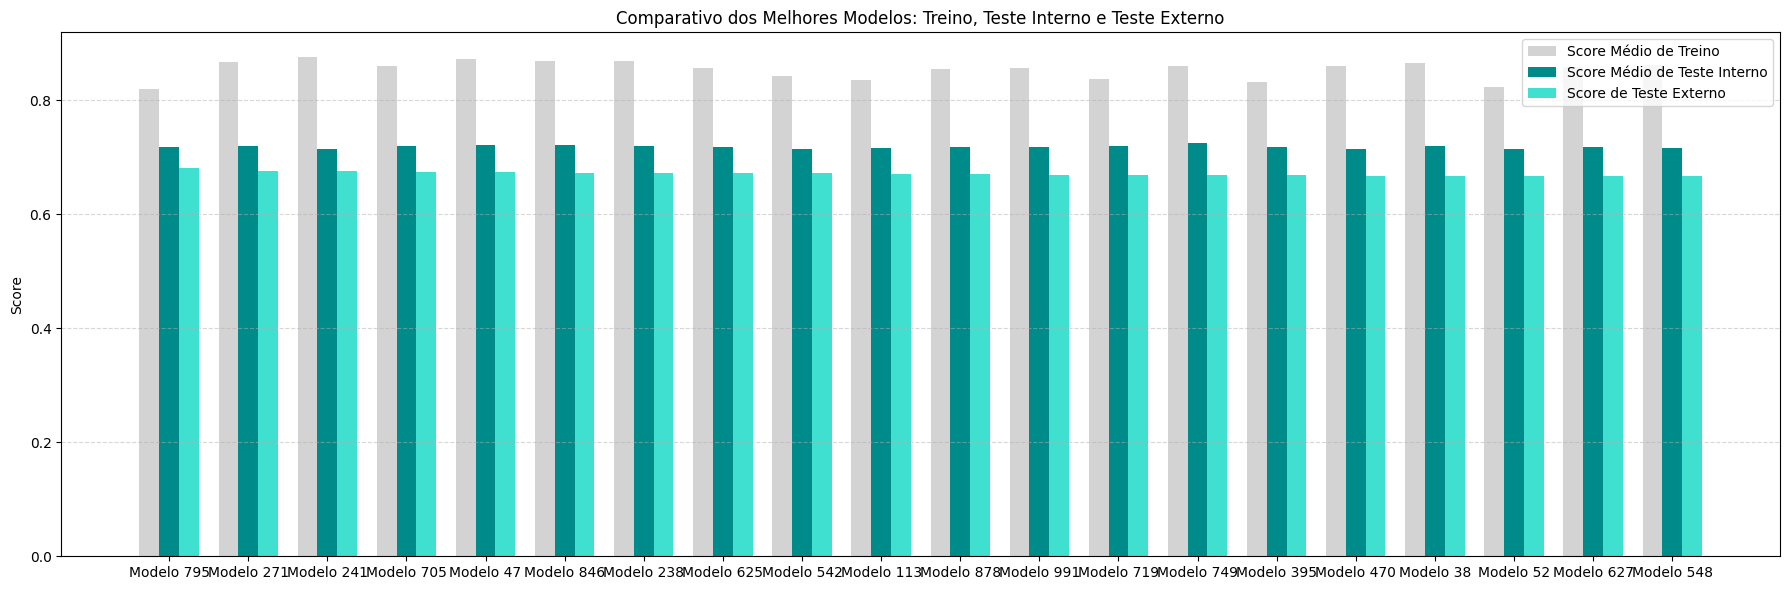

In [23]:
dados_grafico = resultados_filt_ord.head(20)     
x_pos = np.arange(len(dados_grafico))            # Posições dos rótulos do eixo X
largura_barra = 0.25                             # Largura das barras

plt.figure(figsize=(18, 6))
plt.bar(x_pos - largura_barra,                   # Série com score médio de treino
        dados_grafico["media_score_treino"],
        width=largura_barra,
        label="Score Médio de Treino",
        color="lightgray")
plt.bar(x_pos,                                   # Série com score médio de teste interno
        dados_grafico["media_score_teste_interno"],
        width=largura_barra,
        label="Score Médio de Teste Interno",
        color="darkcyan")
plt.bar(x_pos + largura_barra,                   # Série com score médio de teste externo
        dados_grafico["score_teste_externo"],
        width=largura_barra,
        label="Score de Teste Externo",
        color="turquoise")

plt.xticks(x_pos,
           dados_grafico["num_modelo"],
           rotation=0,
           ha='center')
plt.ylabel("Score")
plt.title("Comparativo dos Melhores Modelos: Treino, Teste Interno e Teste Externo")
plt.legend()
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

### **Etapa 7: Escolha do modelo**

*Escolha do modelo*

In [ ]:
num_modelo_escolhido = "Modelo 795"


*Características do modelo escolhido*

In [25]:
linha = resultados.loc[resultados["num_modelo"] == num_modelo_escolhido].squeeze()
nome_algoritmo = linha["nome_algoritmo"]
hiperparametros = linha["hiperparametros"]
classe = algoritmos[nome_algoritmo][0]
print(f"O modelo final adotado foi construído com o algoritmo {nome_algoritmo}, com hiperparâmetros: { {k: round(v, 4) if isinstance(v, float) else v for k, v in hiperparametros.items()} }")

O modelo final adotado foi construído com o algoritmo XGBOOST, com hiperparâmetros: {'colsample_bytree': np.float64(0.5707), 'gamma': np.float64(1.4566), 'learning_rate': np.float64(0.0838), 'max_depth': 5, 'min_child_weight': 12, 'n_estimators': 204, 'reg_alpha': np.float64(4.4733), 'reg_lambda': np.float64(1.4015), 'subsample': np.float64(0.622)}


In [26]:
# 1. Configurar o modelo com os melhores hiperparâmetros encontrados
modelo_final = classe.set_params(**hiperparametros)

# 2. Lógica de Ponderação (Para evitar aplicar peso duas vezes)
# Aplica os pesos das observações ao ajustar o XGBoost.
if "XGB" in type(modelo_final).__name__:
    print(f"Detectado XGBoost: Calculando e aplicando sample_weights manuais...")
    pesos_treino = compute_sample_weight(class_weight='balanced', y=y_treino)
    modelo_final.fit(X_treino_tratada, y_treino, sample_weight=pesos_treino)

# Se for Random Forest ou LightGBM, eles já têm class_weight='balanced' embutido
else:
    print(f"Detectado {type(modelo_final).__name__}: Usando class_weight interno (sem sample_weight)...")
    # Ativa o balanceamento por classe quando o estimador oferece essa opção.
    if hasattr(modelo_final, 'class_weight') and modelo_final.class_weight is None:
        modelo_final.set_params(class_weight='balanced')
        
    modelo_final.fit(X_treino_tratada, y_treino)

print("Modelo Final treinado com sucesso!")

Detectado XGBoost: Calculando e aplicando sample_weights manuais...
Modelo Final treinado com sucesso!


### **Etapa 8: Calibração e análises adicionais no conjunto de teste externo**

*Aplicação do modelo final no conjunto de teste externo*

In [329]:
p_hat_teste = modelo_final.predict_proba(X_teste_tratada)
classes = modelo_final.classes_

*Atribuição da categoria de resposta predita pelo modelo, com base na maior probabilidade*

In [330]:
y_hat_teste = classes[p_hat_teste.argmax(axis=1)]

*Verificação gráfica de calibração das probabilidades*

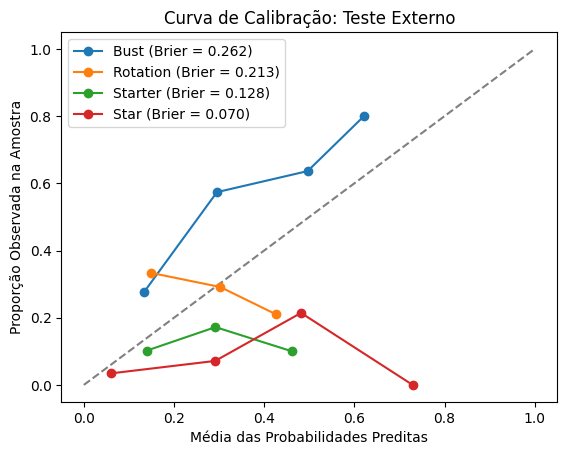

In [331]:
# Cálculos
y_one_hot = label_binarize(y_teste, classes=classes)

# Gráfico da curva de calibração para cada classe (one-versus-rest)
plt.plot([0,1],[0,1],'--', color='gray')
for k, cls in enumerate(classes):
    y_bin = (y_teste == cls).astype(int)
    prop_obs, p_hat_media = calibration_curve(y_bin, p_hat_teste[:, k])
    brier = brier_score_loss(y_bin, p_hat_teste[:, k])
    plt.plot(p_hat_media,
             prop_obs,
             'o-',
             label=f"{ordem_categorias[cls]} (Brier = {brier:.3f})")
plt.xlabel("Média das Probabilidades Preditas")
plt.ylabel("Proporção Observada na Amostra")
plt.title("Curva de Calibração: Teste Externo")
plt.legend()
plt.show()

***(Se necessário)*** *Atualização de probabilidades preditas no teste, por meio de recalibração das probabilidades no conjunto de treino*

In [332]:
# Ajusta a calibração por validação cruzada no treino.
modelo_final_calibrado = CalibratedClassifierCV(modelo_final, method='sigmoid', cv=5)
modelo_final_calibrado.fit(X_treino_tratada, y_treino)

# Armazenamento de probabilidades não calibradas e cálculo das probabilidades calibradas
p_hat_teste_nao_calibradas = p_hat_teste
p_hat_teste = modelo_final_calibrado.predict_proba(X_teste_tratada)

***(Se necessário)*** *Verificação gráfica de calibração das probabilidades - atualização pós-calibração*

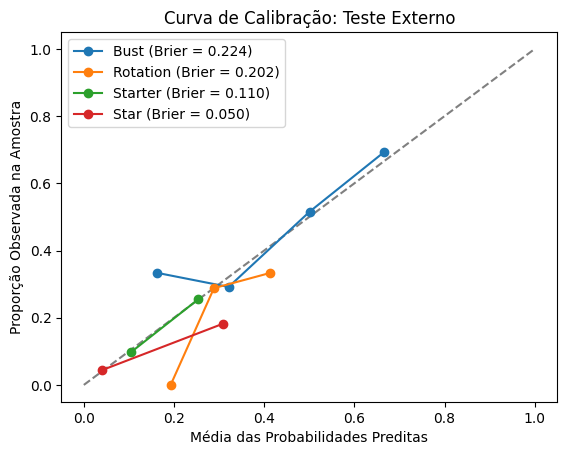

In [333]:
# Cálculos
y_one_hot = label_binarize(y_teste, classes=classes)

# Gráfico da curva de calibração para cada classe (one-versus-rest)
plt.plot([0,1],[0,1],'--', color='gray')
for k, cls in enumerate(classes):
    y_bin = (y_teste == cls).astype(int)
    prop_obs, p_hat_media = calibration_curve(y_bin, p_hat_teste[:, k])
    brier = brier_score_loss(y_bin, p_hat_teste[:, k])
    plt.plot(p_hat_media,
             prop_obs,
             'o-',
             label=f"{ordem_categorias[cls]} (Brier = {brier:.3f})")
plt.xlabel("Média das Probabilidades Preditas")
plt.ylabel("Proporção Observada na Amostra")
plt.title("Curva de Calibração: Teste Externo")
plt.legend()
plt.show()

*Tabela de classificação*

In [334]:
# Tabela de classificação com frequências absolutas
tabela = pd.crosstab(y_teste, y_hat_teste)
tabela.index = np.asarray(ordem_categorias)[tabela.index]
tabela.columns = np.asarray(ordem_categorias)[tabela.columns]
tabela

,Bust,Rotation,Starter,Star
Bust,58,22,11,9
Rotation,23,10,15,7
Starter,5,5,9,7
Star,2,1,3,4


In [335]:
# Tabela de classificação com frequências relativas, somando 100% em cada linha
tabela_relativa_linhas = (tabela.div(tabela.sum(axis=1), axis=0)).round(3)
tabela_relativa_linhas

,Bust,Rotation,Starter,Star
Bust,0.580,0.220,0.110,0.090
Rotation,0.418,0.182,0.273,0.127
Starter,0.192,0.192,0.346,0.269
Star,0.200,0.100,0.300,0.400


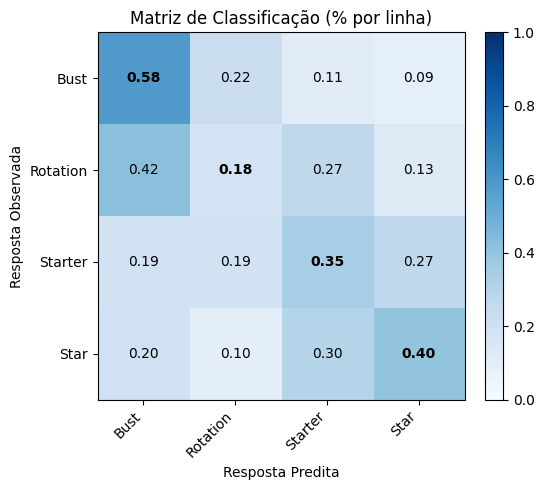

In [336]:
# Gráfico de calor com frequências relativas, somando 100% em cada linha
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(tabela_relativa_linhas.values, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(tabela_relativa_linhas.shape[1]))
ax.set_yticks(range(tabela_relativa_linhas.shape[0]))
ax.set_xticklabels(tabela_relativa_linhas.columns, rotation=45, ha='right')
ax.set_yticklabels(tabela_relativa_linhas.index)
ax.set_xlabel("Resposta Predita"); ax.set_ylabel("Resposta Observada")
ax.set_title("Matriz de Classificação (% por linha)")

for (i, j), v in np.ndenumerate(tabela_relativa_linhas.values):
    same_label = tabela_relativa_linhas.index[i] == tabela_relativa_linhas.columns[j]
    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
            fontweight=("bold" if same_label else "normal"))

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

In [337]:
# Tabela de classificação com frequências relativas, somando 100% em cada coluna
tabela_relativa_colunas = (tabela.div(tabela.sum(axis=0), axis=1)).round(3)
tabela_relativa_colunas

,Bust,Rotation,Starter,Star
Bust,0.659,0.579,0.289,0.333
Rotation,0.261,0.263,0.395,0.259
Starter,0.057,0.132,0.237,0.259
Star,0.023,0.026,0.079,0.148


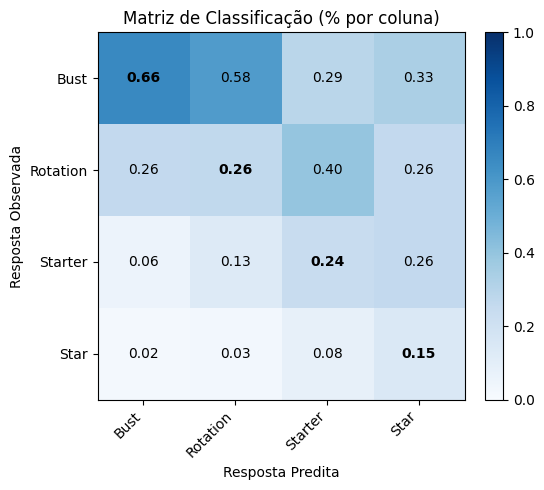

In [338]:
# Gráfico de calor com frequências relativas, somando 100% em cada coluna
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(tabela_relativa_colunas.values, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(tabela_relativa_colunas.shape[1]))
ax.set_yticks(range(tabela_relativa_colunas.shape[0]))
ax.set_xticklabels(tabela_relativa_colunas.columns, rotation=45, ha='right')
ax.set_yticklabels(tabela_relativa_colunas.index)
ax.set_xlabel("Resposta Predita"); ax.set_ylabel("Resposta Observada")
ax.set_title("Matriz de Classificação (% por coluna)")

for (i, j), v in np.ndenumerate(tabela_relativa_colunas.values):
    same_label = tabela_relativa_colunas.index[i] == tabela_relativa_colunas.columns[j]
    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
            fontweight=("bold" if same_label else "normal"))

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

*Desempenho: taxas de acerto por categoria, precisões por categoria, AUC-OVR, acurácia e acurácia balanceada*

In [339]:
# Taxas de acerto por categoria (recalls)
pd.Series(
    np.diag(tabela_relativa_linhas.reindex(columns=tabela_relativa_linhas.index).to_numpy()),
    index=tabela_relativa_linhas.index
)

Bust       0.580
Rotation   0.182
Starter    0.346
Star       0.400
dtype: float64

In [340]:
# Precisões por categoria
pd.Series(
    np.diag(tabela_relativa_colunas.reindex(columns=tabela_relativa_colunas.index).to_numpy()),
    index=tabela_relativa_colunas.index
)

Bust       0.659
Rotation   0.263
Starter    0.237
Star       0.148
dtype: float64

In [341]:
# AUC-OVR, acurácia e acurácia balanceada
auc_ovr = roc_auc_score(y_teste, p_hat_teste, multi_class='ovr', average='weighted')
acuracia = accuracy_score(y_teste, y_hat_teste)
acuracia_balanceada = balanced_accuracy_score(y_teste, y_hat_teste)

print(f'AUC-OVR: {auc_ovr:.3f}')
print(f'Acurácia: {acuracia:.3f}')
print(f'Acurácia balanceada: {acuracia_balanceada:.3f}')

AUC-OVR: 0.663
Acurácia: 0.424
Acurácia balanceada: 0.377


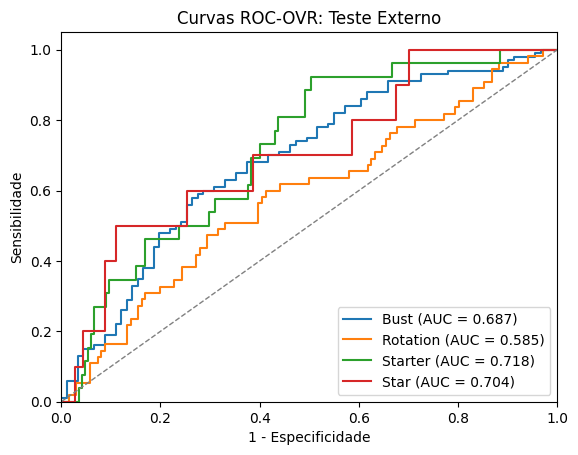

In [342]:
# Exibição das curvas ROC-OVR
plt.figure()
for k, cls in enumerate(classes):
    y_bin = (y_teste == cls).astype(int)
    fpr, tpr, _ = roc_curve(y_bin, p_hat_teste[:, k])
    auc_k = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=1.5, label=f'{ordem_categorias[cls]} (AUC = {auc_k:.3f})')

plt.plot([0, 1], [0, 1], '--', color='gray', lw=1)
plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
plt.xlabel('1 - Especificidade'); plt.ylabel('Sensibilidade')
plt.title('Curvas ROC-OVR: Teste Externo')
plt.legend(loc="lower right")
plt.show()

### **Etapa 9: Interpretabilidade do modelo final**

*Cálculo da importância em redução de impureza para cada variável no modelo final (aplicável apenas para modelos baseados em árvores)*

In [343]:
# Requer um estimador com o atributo feature_importances_.
importancias_impureza = pd.Series(modelo_final.feature_importances_,
                                  index=X_treino_tratada.columns).sort_values()

*Gráfico de importâncias em redução de impureza (aplicável apenas para modelos baseados em árvores)*

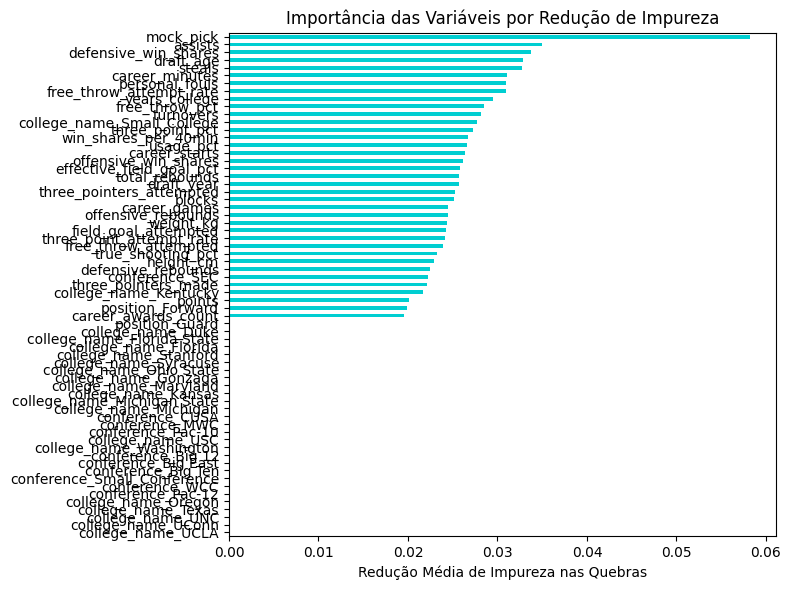

In [344]:
# Requer um estimador com o atributo feature_importances_.
plt.figure(figsize=(8, 6))
importancias_impureza.plot.barh(title="Importância das Variáveis por Redução de Impureza",
                                color="darkturquoise")
plt.xlabel("Redução Média de Impureza nas Quebras")
plt.tight_layout()
plt.show()

*Cálculo da importância por permutação para cada variável no modelo final*

In [345]:
importancias_permutacao = permutation_importance(modelo_final,
                                                 X_treino_tratada,
                                                 y_treino,
                                                 n_repeats=30,
                                                 random_state=123, 
                                                 scoring='roc_auc_ovr')
importancias_permutacao = pd.Series(importancias_permutacao.importances_mean,
                                    index=X_treino_tratada.columns).sort_values()

*Gráfico de importâncias por permutação*

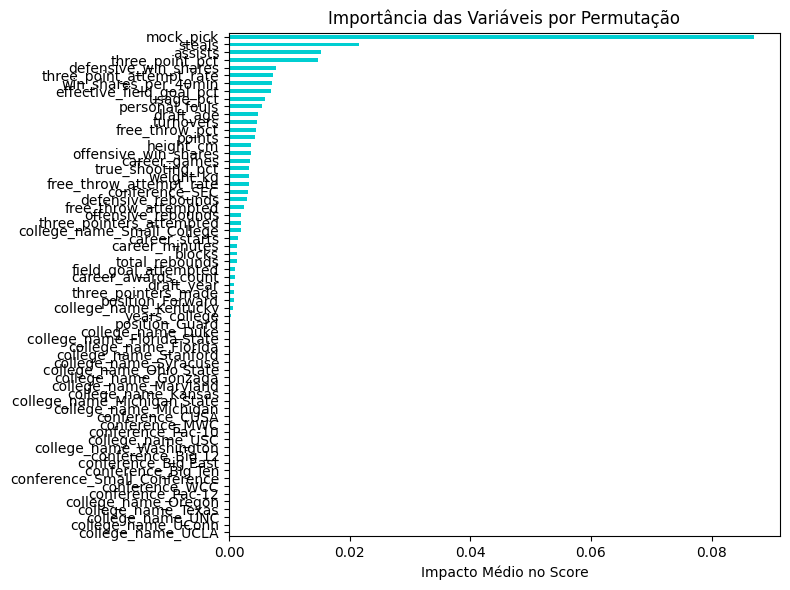

In [346]:
plt.figure(figsize=(8, 6))
importancias_permutacao.plot.barh(title="Importância das Variáveis por Permutação",
                                  color="darkturquoise")
plt.xlabel("Impacto Médio no Score")
plt.tight_layout()
plt.show()

*Cálculo dos valores SHAP das variáveis no modelo final*

In [347]:
if nome_algoritmo not in ['ADABOOST', 'GRADIENT BOOSTING', 'GRADIENT BOOSTING COM HISTOGRAMAS']:
    # Usa as observações de treino como amostra de referência para SHAP.
    X_amostra = shap.sample(X_treino_tratada, X_treino_tratada.shape[0], random_state=123)
    explainer = shap.Explainer(modelo_final, X_amostra)
    valores_shap = explainer(X_amostra)
else:
    # Para AdaBoost, GB e GB com histogramas, a implementação do cálculo de valores SHAP no caso multinomial não é direta; é preciso usar um método mais oneroso computacionalmente, em uma subamostra pequena de observações
    X_amostra = shap.sample(X_treino_tratada, 100, random_state=123)
    explainer = shap.Explainer(modelo_final.predict_proba, X_amostra)
    valores_shap = explainer(X_amostra)



100%|===================| 3039/3052 [00:38<00:00]        

*Gráfico de valores absolutos médios de SHAP*

Gerando SHAP Bar Plot para a classe: Bust


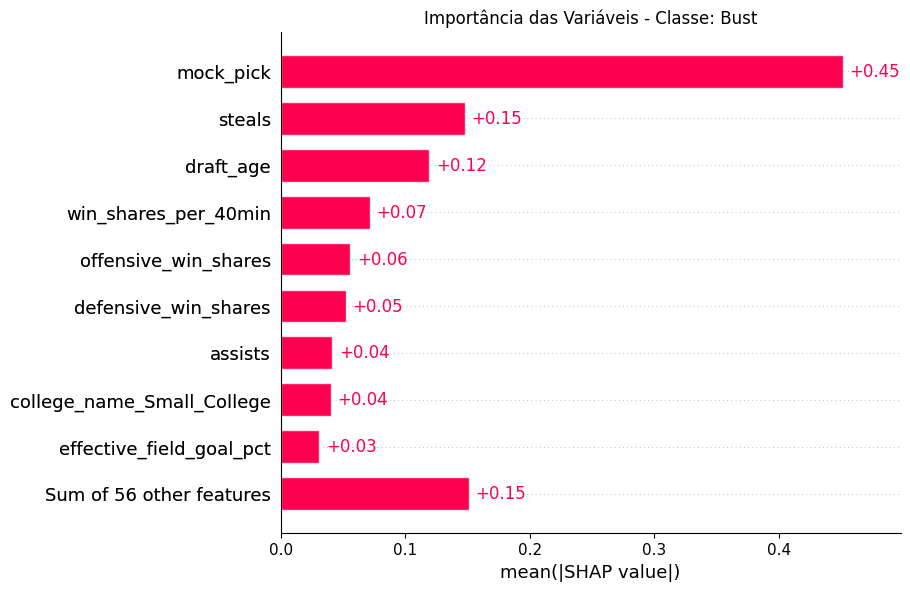

Gerando SHAP Bar Plot para a classe: Rotation


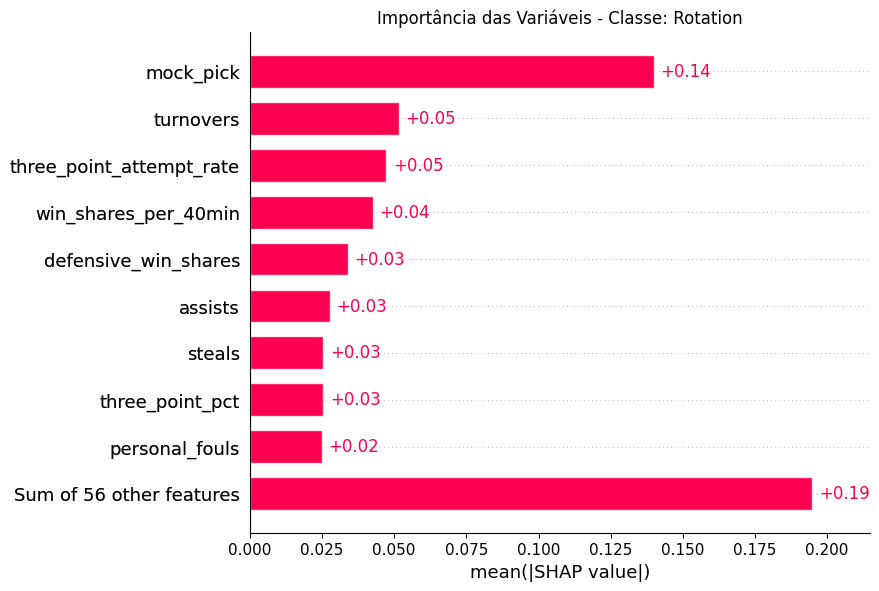

Gerando SHAP Bar Plot para a classe: Starter


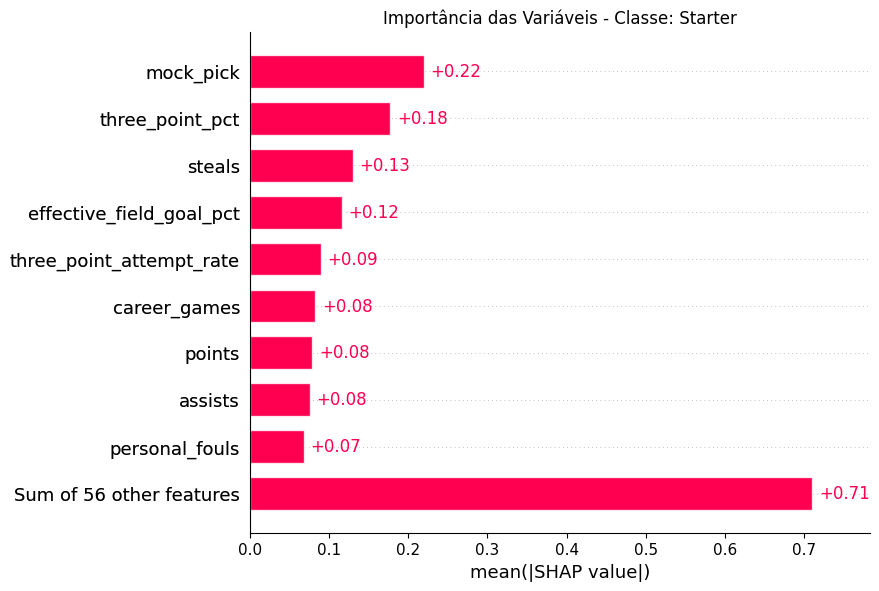

Gerando SHAP Bar Plot para a classe: Star


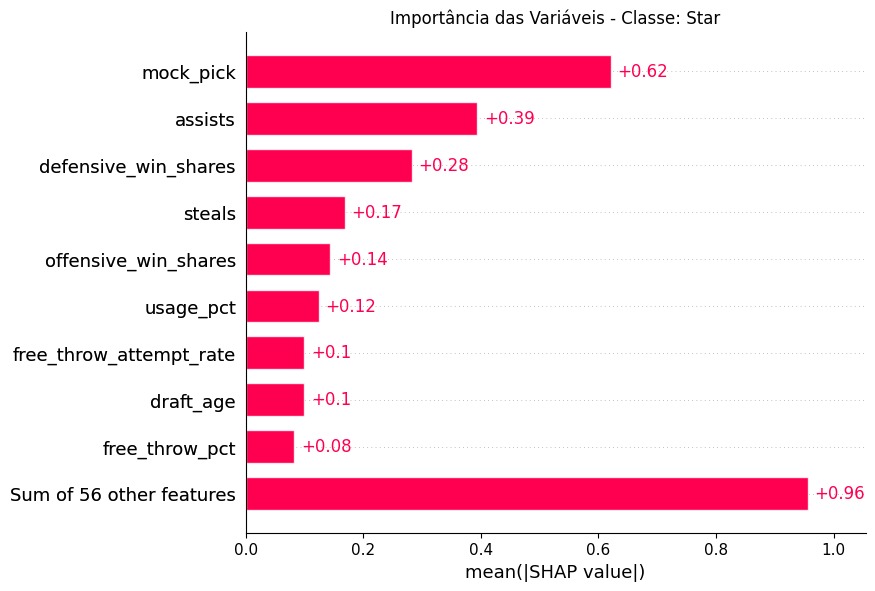

In [348]:
for i, nome in enumerate(ordem_categorias):
    print(f"Gerando SHAP Bar Plot para a classe: {nome}")
    
    # Criar a figura
    plt.figure()
    plt.title(f"Importância das Variáveis - Classe: {nome}")
    
    # Gerar o gráfico de barras para a classe i
    # valores_shap[:,:,i] acessa a explicação específica daquela categoria
    shap.plots.bar(valores_shap[:,:,i], show=False)
    
    plt.show()

    


*Gráfico de direção do impacto baseado em SHAP (beeswarm)*

Gerando SHAP beeswarm para a classe: Bust


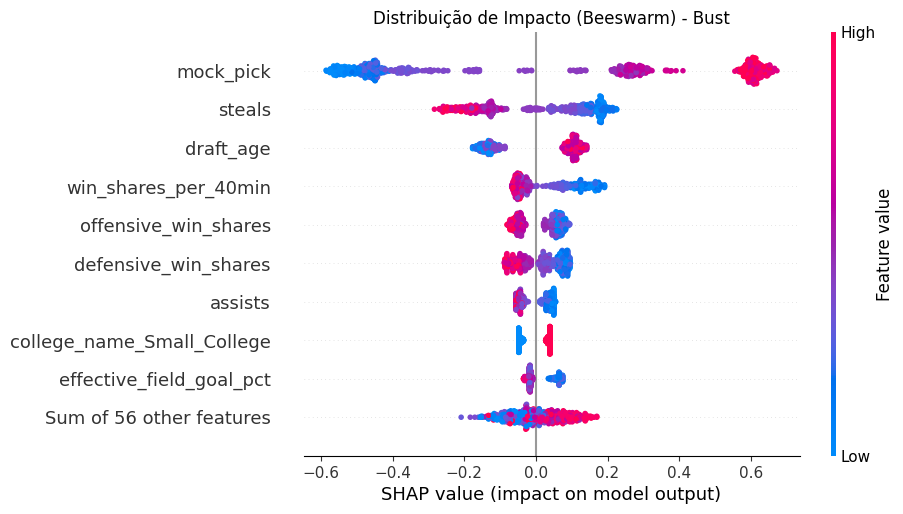

Gerando SHAP beeswarm para a classe: Rotation


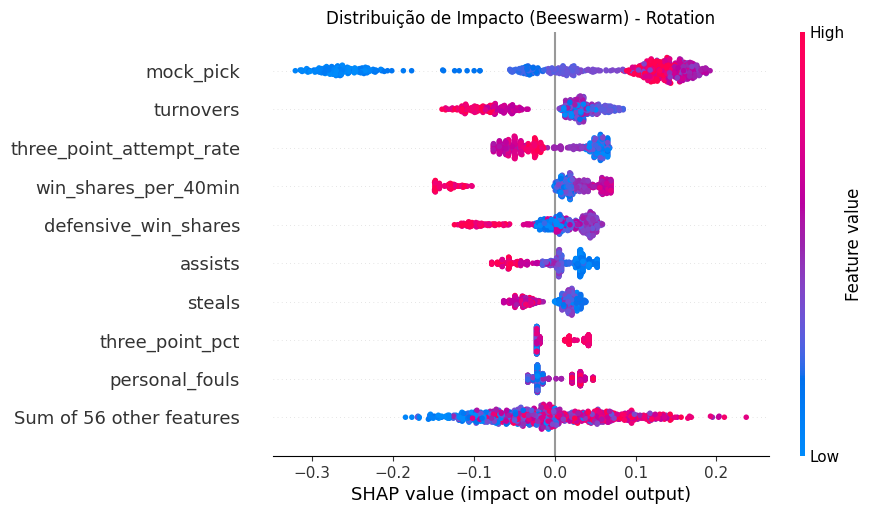

Gerando SHAP beeswarm para a classe: Starter


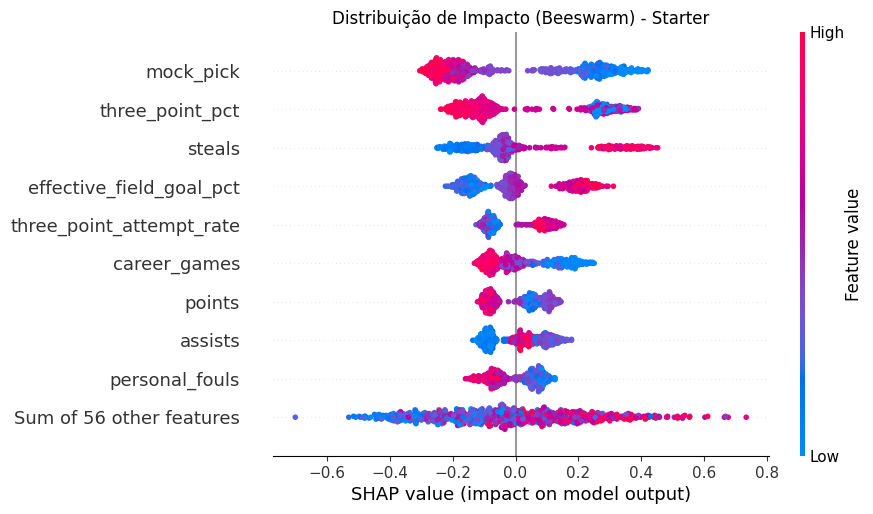

Gerando SHAP beeswarm para a classe: Star


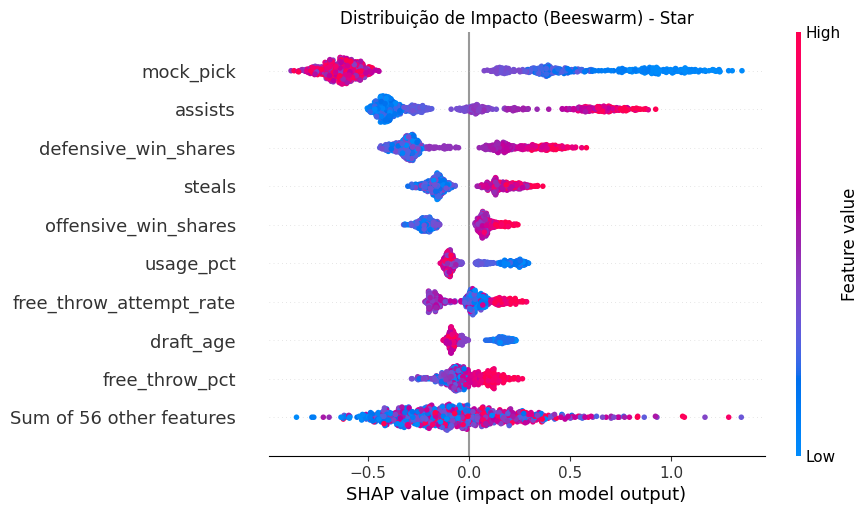

In [349]:
for i, nome in enumerate(ordem_categorias):
    print(f"Gerando SHAP beeswarm para a classe: {nome}")
    
    # Criar a figura
    plt.figure(figsize=(10, 6))
    plt.title(f"Distribuição de Impacto (Beeswarm) - {nome}")
    # Para versões recentes do SHAP, usamos plots.beeswarm
    shap.plots.beeswarm(valores_shap[:, :, i], max_display=10, show=False)
    plt.show()

### **Etapa 10: Mudando Corte**

In [350]:
p_hat_teste = modelo_final.predict_proba(X_teste_tratada)

In [351]:
y_hat_teste_ajustado = []

for prob in p_hat_teste:
    if prob[3] >= 0.20:
        y_hat_teste_ajustado.append('Star')
        
    elif prob[2] >= 0.25:
        y_hat_teste_ajustado.append('Starter')
        
    elif prob[1] >= 0.30:
        y_hat_teste_ajustado.append('Rotation')
        
    else:
        y_hat_teste_ajustado.append('Bust')
y_hat_teste = np.array(y_hat_teste_ajustado)

*Verificação gráfica de calibração das probabilidades*

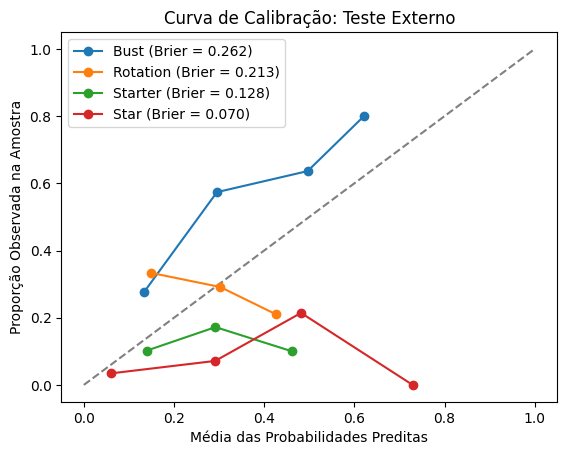

In [352]:
# Cálculos
y_one_hot = label_binarize(y_teste, classes=classes)

# Gráfico da curva de calibração para cada classe (one-versus-rest)
plt.plot([0,1],[0,1],'--', color='gray')
for k, cls in enumerate(classes):
    y_bin = (y_teste == cls).astype(int)
    prop_obs, p_hat_media = calibration_curve(y_bin, p_hat_teste[:, k])
    brier = brier_score_loss(y_bin, p_hat_teste[:, k])
    plt.plot(p_hat_media,
             prop_obs,
             'o-',
             label=f"{ordem_categorias[cls]} (Brier = {brier:.3f})")
plt.xlabel("Média das Probabilidades Preditas")
plt.ylabel("Proporção Observada na Amostra")
plt.title("Curva de Calibração: Teste Externo")
plt.legend()
plt.show()

***(Se necessário)*** *Atualização de probabilidades preditas no teste, por meio de recalibração das probabilidades no conjunto de treino*

In [353]:
# Ajusta a calibração por validação cruzada no treino.
modelo_final_calibrado = CalibratedClassifierCV(modelo_final, method='sigmoid', cv=5)
modelo_final_calibrado.fit(X_treino_tratada, y_treino)

# Armazenamento de probabilidades não calibradas e cálculo das probabilidades calibradas
p_hat_teste_nao_calibradas = p_hat_teste
p_hat_teste = modelo_final_calibrado.predict_proba(X_teste_tratada)

***(Em caso de subamostragem)*** *Correção de probabilidades preditas no teste, por conta de subamostragem*

In [354]:
# Cálculo de razões entre as proporções originais (antes da subamostragem) e das proporções novas (após subamostragem)
dist_y_pre_reamostragem = pd.Series(y_treino).value_counts(normalize=True).reindex(classes).to_numpy()
dist_y_pos_reamostragem = pd.Series(y_treino).value_counts(normalize=True).reindex(classes).to_numpy()
w = dist_y_pre_reamostragem / dist_y_pos_reamostragem

# Armazenamento de probabilidades calibradas e cálculo das probabilidades calibradas + corrigidas após subamostragem
p_hat_teste_calibradas = p_hat_teste
p_hat_teste = p_hat_teste * w
p_hat_teste = p_hat_teste / p_hat_teste.sum(axis=1, keepdims=True)

***(Se necessário)*** *Verificação gráfica de calibração das probabilidades - atualização pós-calibração*

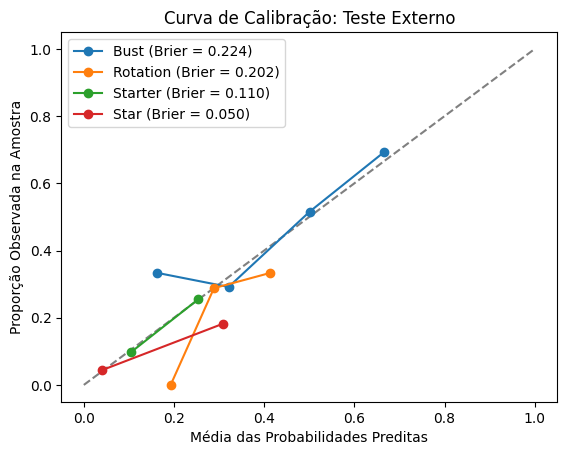

In [355]:
# Cálculos
y_one_hot = label_binarize(y_teste, classes=classes)

# Gráfico da curva de calibração para cada classe (one-versus-rest)
plt.plot([0,1],[0,1],'--', color='gray')
for k, cls in enumerate(classes):
    y_bin = (y_teste == cls).astype(int)
    prop_obs, p_hat_media = calibration_curve(y_bin, p_hat_teste[:, k])
    brier = brier_score_loss(y_bin, p_hat_teste[:, k])
    plt.plot(p_hat_media,
             prop_obs,
             'o-',
             label=f"{ordem_categorias[cls]} (Brier = {brier:.3f})")
plt.xlabel("Média das Probabilidades Preditas")
plt.ylabel("Proporção Observada na Amostra")
plt.title("Curva de Calibração: Teste Externo")
plt.legend()
plt.show()

*Tabela de classificação*

In [356]:
# Tabela de classificação com frequências absolutas
tabela = pd.crosstab(y_teste, y_hat_teste)

# Converte os códigos numéricos das classes em nomes.
mapa_classes = {0: 'Bust', 1: 'Rotation', 2: 'Starter', 3: 'Star'}
tabela.rename(index=mapa_classes, columns=mapa_classes, inplace=True)
tabela = tabela.reindex(index=ordem_categorias, columns=ordem_categorias, fill_value=0)

display(tabela)

col_0,Bust,Rotation,Starter,Star
target_label,,,,
Bust,27,38,18,17
Rotation,9,15,17,14
Starter,0,7,10,9
Star,1,2,2,5


In [357]:
# Tabela de classificação com frequências relativas, somando 100% em cada linha
tabela_relativa_linhas = (tabela.div(tabela.sum(axis=1), axis=0)).round(3)
tabela_relativa_linhas

col_0,Bust,Rotation,Starter,Star
target_label,,,,
Bust,0.270,0.380,0.180,0.170
Rotation,0.164,0.273,0.309,0.255
Starter,0.000,0.269,0.385,0.346
Star,0.100,0.200,0.200,0.500


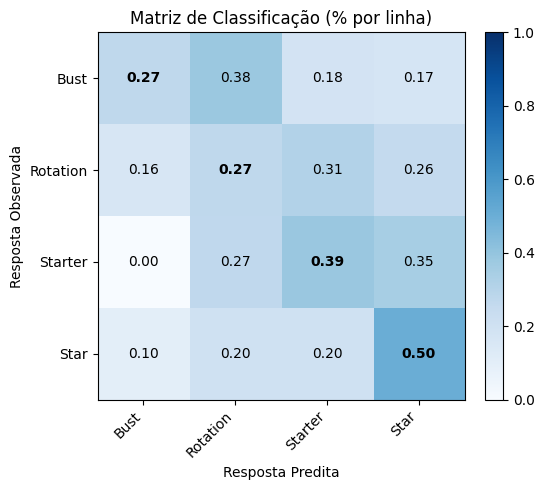

In [358]:
# Gráfico de calor com frequências relativas, somando 100% em cada linha
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(tabela_relativa_linhas.values, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(tabela_relativa_linhas.shape[1]))
ax.set_yticks(range(tabela_relativa_linhas.shape[0]))
ax.set_xticklabels(tabela_relativa_linhas.columns, rotation=45, ha='right')
ax.set_yticklabels(tabela_relativa_linhas.index)
ax.set_xlabel("Resposta Predita"); ax.set_ylabel("Resposta Observada")
ax.set_title("Matriz de Classificação (% por linha)")

for (i, j), v in np.ndenumerate(tabela_relativa_linhas.values):
    same_label = tabela_relativa_linhas.index[i] == tabela_relativa_linhas.columns[j]
    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
            fontweight=("bold" if same_label else "normal"))

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

In [359]:
# Tabela de classificação com frequências relativas, somando 100% em cada coluna
tabela_relativa_colunas = (tabela.div(tabela.sum(axis=0), axis=1)).round(3)
tabela_relativa_colunas

col_0,Bust,Rotation,Starter,Star
target_label,,,,
Bust,0.730,0.613,0.383,0.378
Rotation,0.243,0.242,0.362,0.311
Starter,0.000,0.113,0.213,0.200
Star,0.027,0.032,0.043,0.111


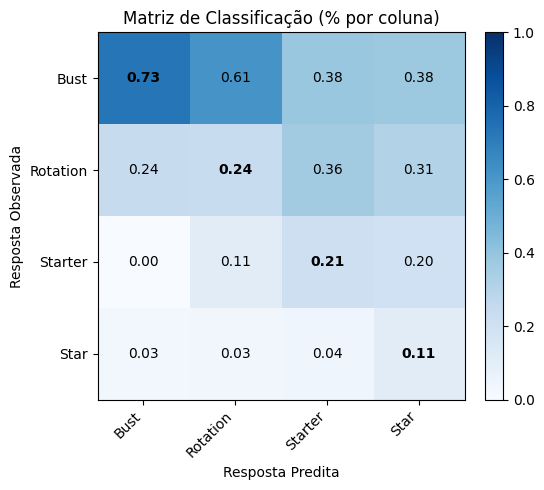

In [360]:
# Gráfico de calor com frequências relativas, somando 100% em cada coluna
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(tabela_relativa_colunas.values, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(tabela_relativa_colunas.shape[1]))
ax.set_yticks(range(tabela_relativa_colunas.shape[0]))
ax.set_xticklabels(tabela_relativa_colunas.columns, rotation=45, ha='right')
ax.set_yticklabels(tabela_relativa_colunas.index)
ax.set_xlabel("Resposta Predita"); ax.set_ylabel("Resposta Observada")
ax.set_title("Matriz de Classificação (% por coluna)")

for (i, j), v in np.ndenumerate(tabela_relativa_colunas.values): 
    same_label = tabela_relativa_colunas.index[i] == tabela_relativa_colunas.columns[j] 
    
    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
            fontweight=("bold" if same_label else "normal"))

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

*Desempenho: taxas de acerto por categoria, precisões por categoria, AUC-OVR, acurácia e acurácia balanceada*

In [361]:
# Taxas de acerto por categoria (recalls)
pd.Series(
    np.diag(tabela_relativa_linhas.reindex(columns=tabela_relativa_linhas.index).to_numpy()),
    index=tabela_relativa_linhas.index
)

target_label
Bust       0.270
Rotation   0.273
Starter    0.385
Star       0.500
dtype: float64

In [362]:
# Precisões por categoria
pd.Series(
    np.diag(tabela_relativa_colunas.reindex(columns=tabela_relativa_colunas.index).to_numpy()),
    index=tabela_relativa_colunas.index
)

target_label
Bust       0.730
Rotation   0.242
Starter    0.213
Star       0.111
dtype: float64

In [363]:
y_teste_texto = y_teste.map(mapa_classes)
auc_ovr = roc_auc_score(y_teste, p_hat_teste, multi_class='ovr', average='weighted')

# Calcula as acurácias usando os nomes das classes.
acuracia = accuracy_score(y_teste_texto, y_hat_teste)
acuracia_balanceada = balanced_accuracy_score(y_teste_texto, y_hat_teste)

print(f'AUC-OVR: {auc_ovr:.3f}')
print(f'Acurácia: {acuracia:.3f}')
print(f'Acurácia balanceada: {acuracia_balanceada:.3f}')

AUC-OVR: 0.663
Acurácia: 0.298
Acurácia balanceada: 0.357
